# Fewer Intermediates, Measured Costs

## Reproducible RMSNorm kernel optimization across CPU and a local GPU supplement

Technical artifact paper. CPU and Metal measurements are real; the supplied CUDA/HIP Triton kernel and FlagOS target hardware were not executed on this host.

## Abstract

Kernel-optimization claims are difficult to assess when numerical correctness, allocation costs, synchronization and hardware provenance are omitted. This artifact implements and measures RMSNorm through a materialized NumPy reference and a reduction-fused CPU path. It also supplies a masked Triton kernel for supported CUDA/HIP devices and a separately labelled Metal kernel that can be exercised on the available Apple Silicon host. The CPU optimization avoids allocating a full squared matrix. The Metal implementation fuses reduction, inverse-root normalization and affine weighting within a row threadgroup. Every measured implementation is checked against a numerical reference before timing. Four shapes include a non-power-of-two feature axis. Warmups, fifty repeated timings, median, p95, aggregate duration, source hashes and backend capability records are included. The local measurements show shape-dependent costs and improvements, not an accelerator-independent speedup. No Metal result is presented as Triton performance or FlagOS compliance. The contribution is a reproducible optimization and validation artifact with an executable notebook and a clear distinction between measured backends and code awaiting target-hardware evaluation.

## 1. Motivation

Normalization kernels often combine a reduction with elementwise operations. A straightforward expression can create large intermediate arrays or multiple device launches. Fusing those operations can reduce memory traffic and launch overhead, but numerical order, synchronization costs and tensor shape can change the benefit.

The research question is whether a small kernel experiment can make those tradeoffs measurable without substituting theoretical throughput or a different backend for the requested target. The artifact therefore records numerical error alongside timing and reports capability failures explicitly.

RMSNorm is selected because its contract is compact enough to inspect. The experiment is not a full transformer benchmark, a training optimization, a FlagOS hardware comparison or a claim about every normalization workload.

## 2. Numerical contract

For a row x of D features, feature weight w and epsilon positive,

```text
r = reciprocal_sqrt(mean(x * x) + epsilon)
y = x * r * w
```

The evaluated contract uses float32 inputs and weights with epsilon equal to 1e-6. Rows and features are nonempty, the weight vector matches the feature axis and inputs must be finite. The benchmark validates shape and finite-value preconditions before timing.

Each optimized result is compared with the reference using relative and absolute tolerances of 2e-5. Maximum absolute error is recorded from actual output arrays. Floating-point reduction order differs between NumPy, a GPU tree reduction and device expression kernels, so bit-for-bit equality is not required.

Tests include zeros, very small values, ordinary random values, large values and non-power-of-two feature counts. A zero row remains well-defined because epsilon is positive. These checks test the specified numeric range, not all finite values close to overflow or every mixed-precision regime.

## 3. Implementations

### 3.1 Materialized CPU reference

The reference constructs x squared, computes its row mean, adds epsilon, normalizes x and applies the weights. It is a concise NumPy expression and intentionally exposes the allocation cost of a full squared matrix.

### 3.2 Reduction-fused CPU path

The optimized CPU implementation uses an einsum dot reduction of each row with itself. It does not materialize the full squared tensor. It computes one inverse-root value per row and uses output-buffer multiplication for normalization and affine weighting.

This is a C-level NumPy reduction optimization, not a Triton kernel or a hand-written SIMD implementation. It still performs separate output multiplications and allocates an output array. No measured DRAM bandwidth or instruction-level fusion is inferred solely from the code.

### 3.3 CUDA/HIP Triton kernel

The optional kernel launches one program per row. It loads a power-of-two feature block with a mask, accumulates squared values in float32, divides by the true feature count and applies inverse-root normalization and weights before masked storage.

Masking distinguishes actual features from padding. The true D appears in the mean denominator. The wrapper requires a supported contiguous device tensor and matching weights. Warp-count calibration uses a separate allocation, and the benchmark selects a calibrated setting before evaluating the measured tensor.

The GPU path uses synchronized Triton benchmark timing and checks against a PyTorch reference. This code is included for a supported target host. It was not executed in the local report because the installed host does not expose a supported CUDA/HIP environment. Asking explicitly for the GPU backend fails instead of silently relabelling CPU data.

### 3.4 Supplemental Metal kernel

The available host can run an Apple Silicon Metal experiment through MLX. It is supplied as a separate backend and never treated as a Triton implementation.

Each row uses a 256-thread group. Threads accumulate strided feature squares, share partial sums and perform a synchronized tree reduction. Threads then normalize and weight their assigned columns. The kernel supports the measured float32 contract and a bounded feature count.

The comparison is an MLX expression implementation versus this custom Metal kernel. Both produce actual arrays and are synchronized with evaluation and device synchronization on every timed call. Kernel creation and compilation occur before warmup.

The supplement allows genuine local GPU experimentation without inventing a CUDA result. It does not validate the FlagOS software stack, device portability, vendor-specific performance or any competition requirement.

## 4. Experimental protocol

Four tensor shapes are evaluated. They include a small 32-by-128 matrix, a 512-by-1024 matrix, a larger 1024-by-4096 matrix and a 33-by-513 matrix that exercises non-power-of-two feature masking.

Inputs and weights are generated from a recorded seed. Each shape uses one generated allocation pair repeatedly. This is a controlled microbenchmark rather than fifty independently sampled workload distributions.

Numerical comparison happens before measurement. Ten warmup calls precede fifty recorded CPU or Metal calls. CPU timers use a high-resolution performance counter. Metal calls force actual evaluation and synchronization, so lazy graph construction is not mistaken for completed GPU execution.

The measured functions include output allocation and normal call overhead. Input generation, numerical validation and one-time kernel compilation are outside the timing interval. The reference and optimized paths follow the same timing convention within each backend.

The ledger records backend, implementation, matrix shape, dtype, maximum error, warp setting when applicable, median time, p95 time and aggregate time. Runtime summaries are generated directly from observed samples. No hand-entered performance table is used.

## 5. Local results

The CPU fused-reduction path improves the observed median time on the measured shapes, with magnitude depending on shape and local memory behavior. The exact timings and error values appear in the generated appendix.

The Metal fused kernel is also measured against the device expression reference. The larger matrix can benefit from reducing multiple launches and intermediates, whereas very small shapes are dominated by dispatch and synchronization overhead. A GPU is not automatically faster than NumPy for a small matrix.

CPU and Metal times are useful operational observations, but they have different call and synchronization costs. Primary optimization conclusions are therefore drawn within each backend, not by presenting every cross-backend ratio as a hardware-neutral result.

All reported arrays pass the stated tolerance checks. The recorded absolute errors are small but nonzero, which is consistent with changed floating-point reduction order. Passing the tested tolerance does not prove numerical behavior for arbitrary extreme inputs.

There are no Triton rows in the local measurement table. The capability record explicitly states that no supported local CUDA/HIP setup was used. There is likewise no FlagOS accelerator measurement. An unexecuted kernel is not reported as a successful speedup.

## 6. Interpretation

Removing an intermediate can help a memory-oriented operation, but its benefit cannot be derived from source count alone. NumPy implementation details, allocator reuse, cache state, matrix dimensions and device launch cost all contribute.

The optimized CPU expression avoids the squared matrix but still reads source values in a reduction and writes an output. The benchmark does not directly measure memory-controller traffic. Statements about reduced materialization are implementation facts; statements about achieved bandwidth would require a separate profiler experiment.

On Metal, the row reduction uses synchronization and shared storage. Those costs can outweigh launch savings on a small tensor. A wider feature axis changes the amount of work per thread and the reduction-to-elementwise ratio. The measured shape dependence is therefore expected and must remain visible.

Warp-count tuning in the optional Triton path is also target-specific. The best calibrated setting on one CUDA or HIP device may not be best elsewhere. Tuning must be repeated on the actual challenge hardware with the documented numerical and timing contract.

## 7. Reproduction and backend handling

The CPU path requires only the pinned research dependencies. The optional Metal dependency is platform-qualified for Apple Silicon. A separate GPU requirements file documents the supported Python environment for PyTorch and Triton.

The backend selector supports CPU, Metal, GPU and automatic capability selection. Explicitly requested unavailable accelerators produce an unavailable result and nonzero exit status. Automatic selection reports which backends were actually executed and retains the unavailable capability record for others.

The paper notebook reruns the benchmark on the reader's host. On a CPU-only Linux system it produces CPU measurements, not the local report's Metal measurements. On a supported GPU host it can produce genuine Triton measurements. Readers must compare backend provenance before comparing timings.

Source hashes identify the CPU benchmark, Triton kernel and Metal kernel separately. That prevents a later kernel change from being silently associated with an earlier performance table. The dependency lock includes platform markers and package hashes.

## 8. Threats to validity and target validation

Warm runs reuse allocations and caches, so they do not model cold startup, memory pressure or competing workloads. The fifty timing samples can be temporally correlated. Median and p95 are descriptive statistics, not a claim of independent-sample statistical significance.

The evaluated contract is float32 with selected finite-value tests. Training gradients, quantized weights, tensor parallelism, fused residual operations and full-model end-to-end speed are not evaluated. A normalization microbenchmark alone cannot establish a language model throughput improvement.

Triton code was not executed on this host. Syntax and wrapper inspection cannot replace target-device validation. Before any FlagOS submission claims performance, the exact target stack, device, supported dtype, compiler version and comparison baseline must be established and the kernel must be run there.

The Metal supplement is useful local engineering evidence but not a workaround for target compliance. The official upstream Triton Apple Metal backend proposal inspected during this work was closed without merge. The local measurements retain their actual MLX/Metal label.

There is no claim of contest acceptance, financial reward, portability across all accelerators or zero numerical error. Those claims require evidence that this artifact does not provide.

## 9. Conclusion

A small RMSNorm study can expose correctness and performance together. The measured CPU and supplemental Metal implementations show real, shape-dependent optimization effects under a stated contract. The unmeasured Triton path is provided for genuine target-host reproduction, not substituted performance. The central contribution is a traceable evaluation process that does not hide backend availability, output allocation, synchronization or numerical limits.

## References

1. Biao Zhang and Rico Sennrich. Root Mean Square Layer Normalization, 2019. [arXiv 1910.07467](https://arxiv.org/abs/1910.07467).
2. Triton project. [Layer normalization tutorial](https://triton-lang.org/main/getting-started/tutorials/05-layer-norm.html).
3. Triton project. [Source repository](https://github.com/triton-lang/triton).
4. MLX project. [Custom Metal kernels](https://ml-explore.github.io/mlx/build/html/dev/custom_metal_kernels.html).
5. Triton project. [Unmerged Apple Metal backend proposal](https://github.com/triton-lang/triton/pull/10783). This reference documents the checked platform limitation, not an implemented dependency.

## Executable reproduction

The next cell reruns the actual benchmark. Only the bundled public data and synthetic fixtures are used. Install the pinned requirements first. Hardware-dependent timings may change. Unavailable GPU backends are not relabelled as CPU results.

## Recomputed empirical results

| backend | implementation | rows | features | dtype | max_absolute_error | num_warps | median_ms | p95_ms | total_ms |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| cpu | numpy_materialized | 32 | 128 | float32 | 0.000001 | 0 | 0.005292 | 0.005523 | 0.266541 |
| cpu | numpy_fused_reduction | 32 | 128 | float32 | 0.000001 | 0 | 0.004250 | 0.004542 | 0.213791 |
| cpu | numpy_materialized | 512 | 1024 | float32 | 0.000003 | 0 | 0.207271 | 0.218148 | 10.388126 |
| cpu | numpy_fused_reduction | 512 | 1024 | float32 | 0.000003 | 0 | 0.167042 | 0.180298 | 8.481123 |
| cpu | numpy_materialized | 1024 | 4096 | float32 | 0.000004 | 0 | 1.858521 | 2.141811 | 95.341668 |
| cpu | numpy_fused_reduction | 1024 | 4096 | float32 | 0.000004 | 0 | 1.671083 | 2.075625 | 86.320453 |
| cpu | numpy_materialized | 33 | 513 | float32 | 0.000001 | 0 | 0.011750 | 0.012254 | 0.607873 |
| cpu | numpy_fused_reduction | 33 | 513 | float32 | 0.000001 | 0 | 0.008771 | 0.010902 | 0.457996 |
| metal | mlx_expression | 32 | 128 | float32 | 0.000001 | 0 | 0.335251 | 0.577662 | 17.731752 |
| metal | metal_fused | 32 | 128 | float32 | 0.000001 | 0 | 0.297438 | 0.335067 | 14.352415 |
| metal | mlx_expression | 512 | 1024 | float32 | 0.000001 | 0 | 0.456979 | 1.017002 | 26.101664 |
| metal | metal_fused | 512 | 1024 | float32 | 0.000001 | 0 | 0.382813 | 0.554746 | 19.539042 |
| metal | mlx_expression | 1024 | 4096 | float32 | 0.000003 | 0 | 1.258729 | 1.690733 | 65.603211 |
| metal | metal_fused | 1024 | 4096 | float32 | 0.000003 | 0 | 0.540126 | 0.753245 | 28.215375 |
| metal | mlx_expression | 33 | 513 | float32 | 0.000001 | 0 | 0.207771 | 0.243063 | 10.652541 |
| metal | metal_fused | 33 | 513 | float32 | 0.000001 | 0 | 0.202605 | 0.238016 | 10.373161 |


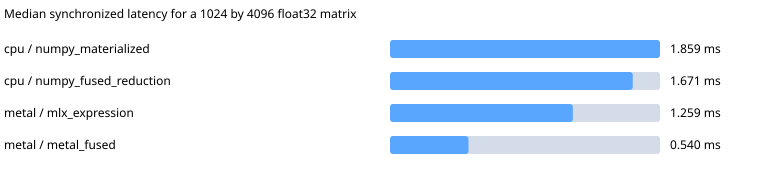

{
  "environment": {
    "system": "Darwin",
    "architecture": "arm64",
    "python": "3.13.18",
    "dependencies": {
      "numpy": "2.3.4",
      "z3-solver": "4.15.3.0",
      "cryptography": "46.0.3"
    }
  },
  "metadata": {
    "seed": 2026,
    "warmup": 10,
    "cpu_repeats": 50,
    "gpu": {
      "available": false,
      "reason": "Optional torch and/or Triton are not installed"
    },
    "gpu_measurements_collected": false,
    "metal": {
      "available": true,
      "backend": "Metal",
      "mlx": "0.29.3"
    },
    "metal_measurements_collected": true,
    "flagos_target_hardware_validated": false,
    "tolerance_rtol": 2e-05,
    "tolerance_atol": 2e-05,
    "benchmark_source_sha256": "09d584c39a212633b6226765906e692b701f9d71323e913c33eacab9f4981b01",
    "triton_kernel_sha256": "a2a870fb8e4fdcd7c9dff71fe9dac902b55008a88c1125d874bbe93722e2599e",
    "metal_kernel_sha256": "8a21e056fffa6d2f44ced43e769029512623c4af267b2ca7422a3f64a2cd1369",
    "common_source_sha2

In [1]:
import json, os, subprocess, sys, tempfile
from pathlib import Path
from IPython.display import display, Markdown, SVG

# Run from the bundle root or the paper directory. No personal path is embedded.
candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for p in candidates if (p / "research_common.py").is_file()), None)
if ROOT is None and Path("/kaggle/input").is_dir():
    mounted = list(Path("/kaggle/input").glob("*/research_common.py"))
    mounted += list(Path("/kaggle/input").glob("*/kaggle_submissions/research_common.py"))
    if len(mounted) == 1:
        ROOT = mounted[0].parent
if ROOT is None:
    raise RuntimeError("Open this notebook within the complete research bundle")
sys.path.insert(0, str(ROOT))
from research_common import markdown_table
from publication_builder import comparison_svg

env = {**os.environ, "OMP_NUM_THREADS": "1", "OPENBLAS_NUM_THREADS": "1", "VECLIB_MAXIMUM_THREADS": "1"}
with tempfile.TemporaryDirectory(prefix="research-reproduction-") as temporary:
    output = Path(temporary)
    child = subprocess.run(
        [sys.executable, str(ROOT / 'flag-os-open-computing-global-challenge-season-2' / 'kernel_benchmark.py'), "--output", str(output)],
        text=True, capture_output=True, env=env, timeout=600,
    )
    if child.returncode:
        raise RuntimeError("Benchmark failed; inspect the local command output")
    report = json.loads((output / "results.json").read_text())

assert report["schema_version"] == 1
assert report["summary"]
display(Markdown("## Recomputed empirical results\n\n" + markdown_table(report["summary"])))
if "acoustic" in report["metadata"]:
    display(Markdown("## Recomputed acoustic results\n\n" + markdown_table(report["metadata"]["acoustic"])))
display(SVG(comparison_svg('flag-os-open-computing-global-challenge-season-2', report)))
print(json.dumps({"environment": report["environment"], "metadata": report["metadata"]}, indent=2))
